# RBM
## Imports

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

from matplotlib import pyplot as plt
from tqdm import tqdm

# Force FP32 computation for GPU-based training (train_rbm_parallel)
policy = tf.keras.mixed_precision.Policy('float32')
tf.keras.mixed_precision.set_global_policy(policy)

I0000 00:00:1793614328.874481  274519 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793614328.903449  274519 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793614329.690702  274519 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## RBM Class and supporting functions
RBM class for single-layer RBM implementation, and other supporting functions to train the model, extract features, save and load weights

In [2]:
class RBM(tf.keras.Model):
    def __init__(self, visible_units, hidden_units, learning_rate=0.01, k=1):
        super(RBM, self).__init__()
        self.visible_units = visible_units
        self.hidden_units = hidden_units
        self.learning_rate = learning_rate
        self.k = k
        
        self.W = self.add_weight(
            shape=(visible_units, hidden_units),
            initializer=tf.random_normal_initializer(stddev=0.01),
            regularizer=tf.keras.regularizers.l2(1e-4),
            name='weights'
        )
        self.hb = self.add_weight(
            shape=(hidden_units,), 
            initializer=tf.zeros_initializer(), 
            name='hidden_bias'
        )
        self.vb = self.add_weight(
            shape=(visible_units,), 
            initializer=tf.zeros_initializer(),
            name='visible_bias'
        )

    def visible_to_hidden(self, v):
        h_prob = tf.nn.sigmoid(tf.matmul(v, self.W) + self.hb)
        return h_prob, tf.nn.relu(tf.sign(h_prob - tf.random.uniform(h_prob.shape)))

    def hidden_to_visible(self, h):
        v_prob = tf.nn.sigmoid(tf.matmul(h, self.W, transpose_b=True) + self.vb)
        return v_prob, tf.nn.relu(tf.sign(v_prob - tf.random.uniform(v_prob.shape)))

    def contrastive_divergence(self, v):
        h_prob, h_sample = self.visible_to_hidden(v)
        v_prob, v_sample = self.hidden_to_visible(h_prob)

        for _ in range(self.k - 1):
            h_prob, h_sample = self.visible_to_hidden(v_sample)
            v_prob, v_sample = self.hidden_to_visible(h_prob)

        return v, v_sample, h_prob, h_sample

    def compute_loss(self, v, v_sample, h_prob, h_sample):
        cross_entropy = -tf.reduce_mean(
            tf.reduce_sum(
                v * tf.math.log(v_prob + 1e-10) + (1 - v) * tf.math.log(1 - v_prob + 1e-10),
                axis=1
            )
        )
        return cross_entropy

    def call(self, v):
        h_prob, _ = self.visible_to_hidden(v)
        return h_prob

    def get_features(self, v):
        return self(v)

    def build(self, input_shape):
        self.W = self.add_weight(shape=(self.visible_units, self.hidden_units),
                                initializer=tf.random_normal_initializer(stddev=0.1),
                                name='weights')
        self.hb = self.add_weight(shape=(self.hidden_units,),
                                 initializer=tf.zeros_initializer(),
                                 name='hidden_bias')
        self.vb = self.add_weight(shape=(self.visible_units,),
                                 initializer=tf.zeros_initializer(),
                                 name='visible_bias')
        super().build(input_shape)
        

In [3]:
def loss_epoch_plot(epochs, losses_vector):
    plt.plot(range(1, epochs + 1), losses_vector)
    plt.title("Loss over epochs")
    plt.show()

In [4]:
def train_rbm(visible_units, hidden_units, data, learning_rate=0.01, k=1, epochs=50, batch_size=32):
    rbm = RBM(visible_units=visible_units, hidden_units=hidden_units, learning_rate=learning_rate, k=k)
    rbm.build((None, visible_units))
    
    optimizer = Adam(learning_rate=learning_rate)
    
    losses = list()
    for epoch in tqdm(range(epochs)):
        epoch_loss = 0.0
        for i in range(0, len(data), batch_size):
            batch = data[i:i+batch_size]
            batch = tf.convert_to_tensor(batch, dtype=tf.float32)

            with tf.GradientTape() as tape:
                v, v_sample, h_prob, h_sample = rbm.contrastive_divergence(batch)
                v_prob = tf.nn.sigmoid(tf.matmul(h_prob, rbm.W, transpose_b=True) + rbm.vb)
                loss = -tf.reduce_mean(tf.reduce_sum(batch * tf.math.log(v_prob + 1e-10) + (1 - batch) * tf.math.log(1 - v_prob + 1e-10), axis=1))

            gradients = tape.gradient(loss, rbm.trainable_variables)
            optimizer.apply_gradients(zip(gradients, rbm.trainable_variables))
            epoch_loss += loss.numpy()

        losses.append(epoch_loss/(len(data)/batch_size))
        # print(f"Epoch {epoch+1}/{epochs}, Loss: {epoch_loss/(len(data)/batch_size):.4f}")
    
    loss_epoch_plot(epochs, losses)
    return rbm

In [5]:
def train_rbm_parallel(visible_units,
                       hidden_units,
                       data,
                       epochs=50, batch_size=256,
                       learning_rate=0.01, k=1,
                       strategy=tf.distribute.MirroredStrategy()):
    with strategy.scope():
        rbm = RBM(visible_units=visible_units, hidden_units=hidden_units, learning_rate=learning_rate, k=k)
        # optimizer = Adam(learning_rate=learning_rate)
        optimizer = Adam(learning_rate=learning_rate, clipvalue=1.0)
        # optimizer = tf.keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9)
        rbm.build((None, visible_units))

    dataset = tf.data.Dataset.from_tensor_slices(data).batch(batch_size, drop_remainder=True).prefetch(tf.data.AUTOTUNE)
    dist_dataset = strategy.experimental_distribute_dataset(dataset)

    @tf.function
    def train_step(batch):
        def step_fn(batch):
            with tf.GradientTape() as tape:
                h_prob, _ = rbm.visible_to_hidden(batch)
                v_prob, _ = rbm.hidden_to_visible(h_prob)
                loss = -tf.reduce_mean(tf.reduce_sum(batch * tf.math.log(v_prob + 1e-10) + (1 - batch) * tf.math.log(1 - v_prob + 1e-10), axis=1))
            gradients = tape.gradient(loss, rbm.trainable_variables)
            optimizer.apply_gradients(zip(gradients, rbm.trainable_variables))
            return loss
        per_replica_loss = strategy.run(step_fn, args=(batch,))
        return strategy.reduce(tf.distribute.ReduceOp.MEAN, per_replica_loss, axis=None)

    losses = list()
    for epoch in tqdm(range(epochs)):
        total_loss = 0.0
        num_batches = 0
        for batch in dist_dataset:
            total_loss += train_step(batch)
            num_batches += 1
        # print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss/num_batches:.4f}")
        losses.append(total_loss/num_batches)

    loss_epoch_plot(epochs, losses)
    return rbm


INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0',)


I0000 00:00:1793614330.839128  274519 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4218 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


In [6]:
def extract_features(rbm, data):
    return rbm.get_features(tf.convert_to_tensor(data, dtype=tf.float32)).numpy()

In [7]:
def save_rbm(rbm, path):
    rbm.save_weights(path)

In [8]:
def load_rbm(visible_units, hidden_units, path):
    rbm = RBM(visible_units, hidden_units)
    rbm.load_weights(path)
    return rbm

## RBM application on preprocessed data
See `01_data_eda.ipynb` for data preprocessed into tensors.

In [9]:
VOCAB_SIZE = 1001

X_raw = np.load('../data/processed/X_raw.npy')
#y_target = np.load('../data/processed/y_target.npy')

print(f"X_raw shape: {X_raw.shape}")

def multi_hot_to_indices(multi_hot_vector):
    vec = np.atleast_1d(multi_hot_vector)
    return [i for i in range(VOCAB_SIZE) if i < len(vec) and vec[i] > 0]


X_raw shape: (95072, 1001)


In [10]:
# Training Variables
HIDDEN_UNITS = 500
VOCAB_SIZE = 1001
EPOCHS = 50
LEARNING_RATE = 0.0001
BATCH_SIZE = 256

  0%|                                                               | 0/50 [00:00<?, ?it/s]I0000 00:00:1793614331.351121  274519 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
/home/parth/Projects/BITS/DM/next-basket-prediction/.venv/lib/python3.14/site-packages/keras/src/optimizers/base_optimizer.py:865: UserWarning: Gradients do not exist for variables ['rbm/weights', 'rbm/hidden_bias', 'rbm/visible_bias'] when minimizing the loss. If using `model.compile()`, did you forget to provide a `loss` argument?
  warnings.warn(
100%|██████████████████████████████████████████████████████| 50/50 [00:36<00:00,  1.36it/s]


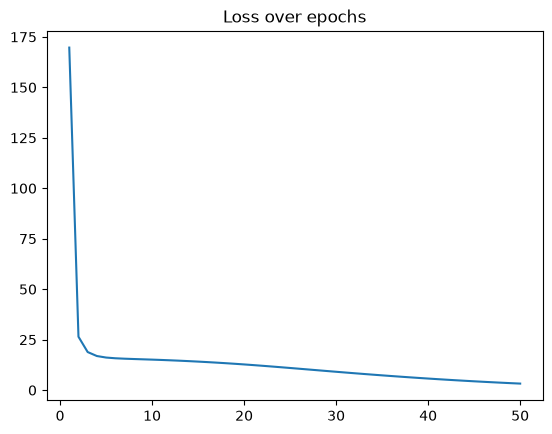

In [11]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    rbm = train_rbm_parallel(
        visible_units=VOCAB_SIZE,
        hidden_units=HIDDEN_UNITS,
        learning_rate=LEARNING_RATE,
        k=1,
        data=X_raw.reshape(-1, VOCAB_SIZE),
        epochs=EPOCHS, batch_size=BATCH_SIZE
    )
else:
    rbm = train_rbm(
        visible_units=VOCAB_SIZE,
        hidden_units=HIDDEN_UNITS,
        learning_rate=LEARNING_RATE,
        k=1,  epochs=EPOCHS, batch_size=BATCH_SIZE,
        data=X_raw.reshape(-1, VOCAB_SIZE)
    )

In [12]:
features = extract_features(rbm, X_raw.reshape(-1, VOCAB_SIZE))

save_rbm(rbm, '../data/rbm/rbm.weights.h5')